In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings("ignore")


# setting up visualization

plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

print("All libraries are completely import")

All libraries are completely import


In [2]:
df = pd.read_csv("retail_sales_dataset.csv")
df.head(10)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


In [3]:
print('Data set Information')

print(f"Dataset Dimension: {df.shape[0]} rows * {df.shape[1]} columns")
print(df.dtypes)

Data set Information
Dataset Dimension: 1000 rows * 9 columns
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object


In [5]:
print(" Null Values")
print(df.isnull().sum())

print("\nData set info \n")

print(df.info())

 Null Values
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Data set info 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB
None


In [56]:
print("data Conversion and Data cleaning")


df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["MonthName"] = df["Date"].dt.month_name()
df["Quarter"] = df["Date"].dt.quarter
df["DayOfWeek"] = df["Date"].dt.day_name()
df["Day"] = df["Date"].dt.day

print(df[["Date", "Year", "Month", "MonthName",
          "Quarter", "DayOfWeek"]].head())



numeric_columns = [
    "Transaction ID",
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nData Types After Conversion:")
print(df.dtypes)

data Conversion and Data cleaning
        Date  Year  Month MonthName  Quarter DayOfWeek
0 2023-11-24  2023     11  November        4    Friday
1 2023-02-27  2023      2  February        1    Monday
2 2023-01-13  2023      1   January        1    Friday
3 2023-05-21  2023      5       May        2    Sunday
4 2023-05-06  2023      5       May        2  Saturday

Data Types After Conversion:
Transaction ID                int64
Date                 datetime64[ns]
Customer ID                  object
Gender                       object
Age                           int64
Product Category             object
Quantity                      int64
Price per Unit                int64
Total Amount                  int64
Month                         int32
Quarter                       int32
DayOFWeek                    object
MonthName                    object
Calculated Amount             int64
Year                          int32
DayOfWeek                    object
Day                           

In [17]:
# Basic statistical summary

print("statistical Summary")
print("Descriptive statistic of numerical column")
print(df[["Transaction ID", "Age", "Total Amount","Product Category"]].describe())

statistical Summary
Descriptive statistic of numerical column
       Transaction ID         Age  Total Amount
count     1000.000000  1000.00000   1000.000000
mean       500.500000    41.39200    456.000000
std        288.819436    13.68143    559.997632
min          1.000000    18.00000     25.000000
25%        250.750000    29.00000     60.000000
50%        500.500000    42.00000    135.000000
75%        750.250000    53.00000    900.000000
max       1000.000000    64.00000   2000.000000


In [18]:
print("Category-wise Average Sales")

category_avg = df.groupby("Product Category")["Total Amount"].mean()

print(category_avg)

Category-wise Average Sales
Product Category
Beauty         467.475570
Clothing       443.247863
Electronics    458.786550
Name: Total Amount, dtype: float64


In [19]:
category_stats = df.groupby("Product Category").agg({
    "Total Amount": ["sum", "mean", "min", "max"],
    "Quantity": "sum",
    "Transaction ID": "count"
})

print(category_stats)

                 Total Amount                       Quantity Transaction ID
                          sum        mean min   max      sum          count
Product Category                                                           
Beauty                 143515  467.475570  25  2000      771            307
Clothing               155580  443.247863  25  2000      894            351
Electronics            156905  458.786550  25  2000      849            342


In [22]:
df["Calculated Amount"] = df["Quantity"] * df["Price per Unit"]

print("Incorrect Amount Records:")

print(df[df["Total Amount"] != df["Calculated Amount"]])

Incorrect Amount Records:
Empty DataFrame
Columns: [Transaction ID, Date, Customer ID, Gender, Age, Product Category, Quantity, Price per Unit, Total Amount, Month, Quarter, DayOFWeek, MonthName, Calculated Amount]
Index: []


In [23]:
print("Product Category Count")

print(df["Product Category"].value_counts())

Product Category Count
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64


In [24]:
print("Gender distribution")
print(df["Gender"].value_counts())

Gender distribution
Gender
Female    510
Male      490
Name: count, dtype: int64


In [32]:
category_sale= df.groupby("Product Category")["Total Amount"].sum()
print(category_sale.sort_values(ascending=False))

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [44]:
category_analysis = df.groupby("Product Category").agg(
    Total_Sales=("Total Amount", "sum"),
    Average_Sales=("Total Amount", "mean"),
    Total_Quantity=("Quantity", "sum"),
    Total_Transactions=("Transaction ID", "count")
)

print(category_analysis)

                  Total_Sales  Average_Sales  Total_Quantity  \
Product Category                                               
Beauty                 143515     467.475570             771   
Clothing               155580     443.247863             894   
Electronics            156905     458.786550             849   

                  Total_Transactions  
Product Category                      
Beauty                           307  
Clothing                         351  
Electronics                      342  


In [45]:
gender_analysis = df.groupby("Gender").agg(
    Total_Sales=("Total Amount", "sum"),
    Average_Sales=("Total Amount", "mean"),
    Total_Transactions=("Transaction ID", "count")
)

print(gender_analysis)

        Total_Sales  Average_Sales  Total_Transactions
Gender                                                
Female       232840     456.549020                 510
Male         223160     455.428571                 490


In [57]:
weekday_sales = df.groupby("DayOfWeek")["Total Amount"].sum()

print(weekday_sales)

DayOfWeek
Friday       66290
Monday       70250
Saturday     78815
Sunday       58600
Thursday     53835
Tuesday      69440
Wednesday    58770
Name: Total Amount, dtype: int64


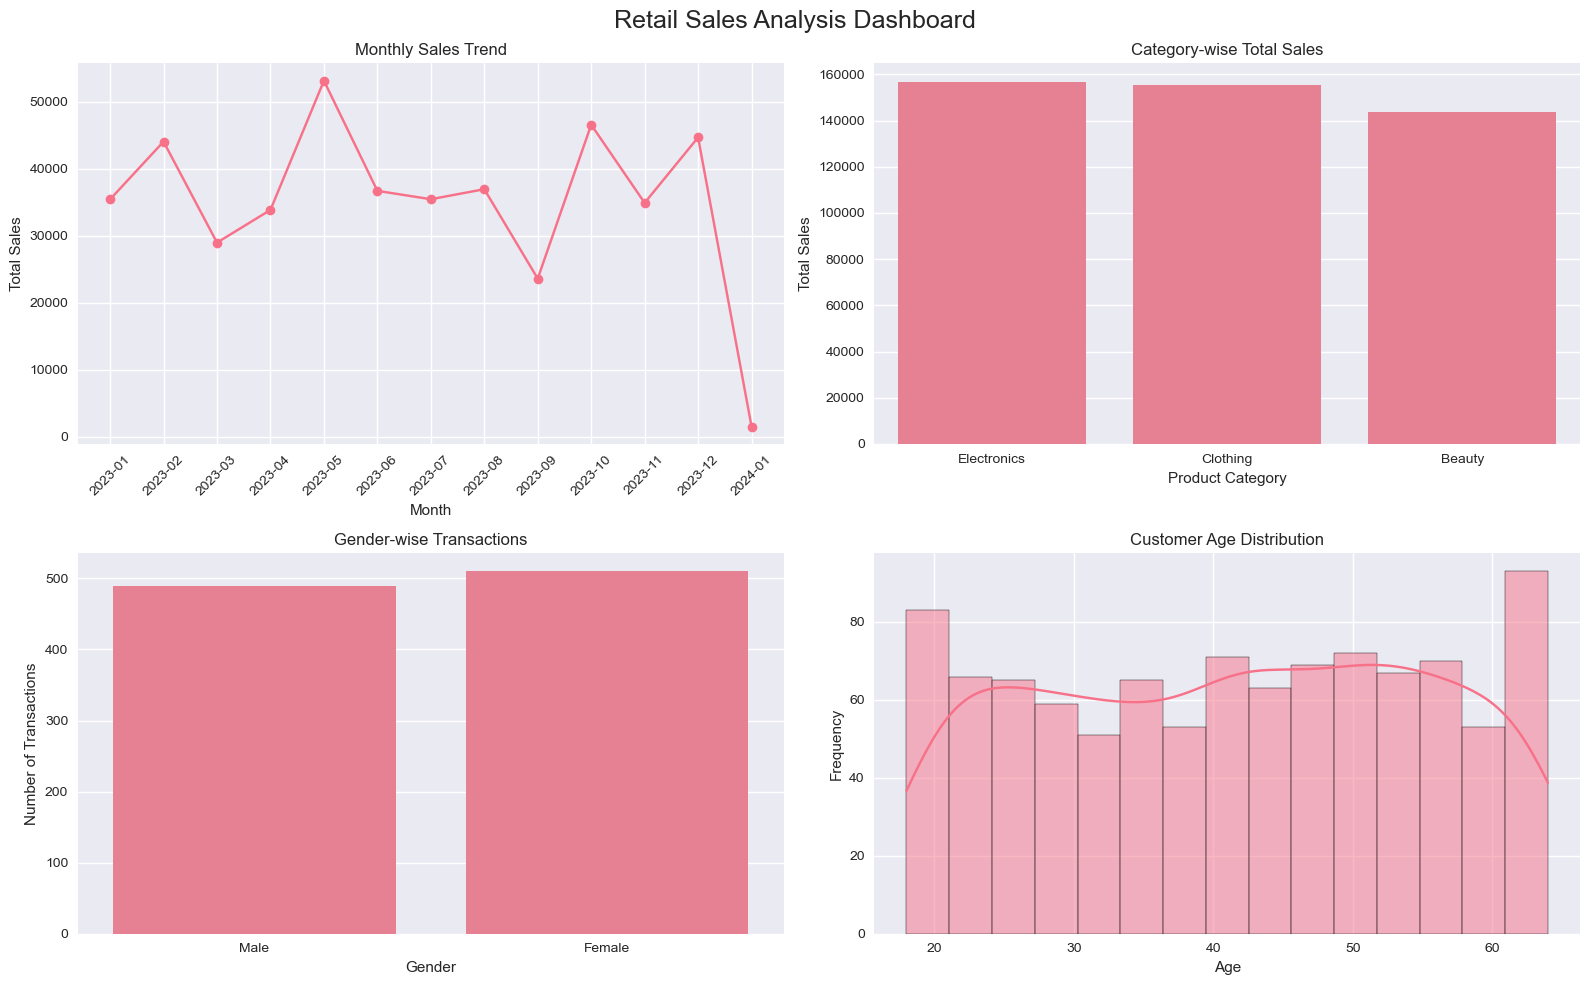

In [58]:

# Create 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Chart 1: Monthly Sales Trend
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Total Amount"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

axes[0, 0].plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Total Sales")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True)


# Chart 2: Top Product Categories
category_sales = df.groupby(
    "Product Category"
)["Total Amount"].sum().sort_values(ascending=False)

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Category-wise Total Sales")
axes[0, 1].set_xlabel("Product Category")
axes[0, 1].set_ylabel("Total Sales")


# Chart 3: Gender-wise Transactions
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Gender-wise Transactions")
axes[1, 0].set_xlabel("Gender")
axes[1, 0].set_ylabel("Number of Transactions")


# Chart 4: Customer Age Distribution
sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Customer Age Distribution")
axes[1, 1].set_xlabel("Age")
axes[1, 1].set_ylabel("Frequency")


# Dashboard title and layout
fig.suptitle(
    "Retail Sales Analysis Dashboard",
    fontsize=18
)

plt.tight_layout()
plt.show()



In [59]:
# Highest selling category
best_category = category_sales.idxmax()

# Highest sales month
best_month = monthly_sales.idxmax()

print("Business Insights")

print("Best Selling Category:", best_category)

print("Highest Sales Month:", best_month)

print("Total Revenue:", df["Total Amount"].sum())

print("Average Transaction:",
      df["Total Amount"].mean())

Business Insights
Best Selling Category: Electronics
Highest Sales Month: 2023-05
Total Revenue: 456000
Average Transaction: 456.0
